# Análisis comparativo sobre 200 correos: Rspamd vs. LLM+MCP (veredicto) vs. LLM+MCP (explicación)

Extiende `analisis_comparativo_100.ipynb` a los 200 correos de `eval_external_200.csv` (100 phishing de
Phishing Pot + 100 legítimos de TREC 2007): los 100 de la primera submuestra más los 100 añadidos después.

- **Rspamd**: filtro basado en reglas (resultados tomados de la corrida sobre los 1,000 correos).
- **LLM+MCP, modo veredicto**: orquestador con los servidores archetype + virustotal (corrida sobre los 1,000).
- **LLM+MCP, modo explicación**: orquestador con los cuatro servidores MCP, evaluado en dos lotes
  (`results_explicacion_100.jsonl` y `results_explicacion_101_200.jsonl`).

La última sección compara el lote 1–100 con el lote 101–200.

## 1. Imports y carga de datos

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import binomtest, fisher_exact
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 150, "savefig.bbox": "tight"})

# Carpeta experiments/ (funciona si el notebook se ejecuta desde experiments/ o desde la raíz del repo)
BASE = Path.cwd() if (Path.cwd() / "eval_system").exists() else Path.cwd() / "experiments"

RUTA_CSV = BASE / "external_eval" / "eval_external_200.csv"
RUTA_RSPAMD = BASE / "eval_system" / "rspamd_results_raw.jsonl"
# Modo explicación: un JSONL por lote
RUTAS_EXPLICACION = {
    "1-100": BASE / "eval_system" / "results_explicacion_100.jsonl",
    "101-200": BASE / "eval_system" / "results_explicacion_101_200.jsonl",
}
# results_raw.jsonl (modo veredicto) puede estar en experiments/data/ o en data/ (raíz del repo)
RUTAS_VEREDICTO = [BASE / "data" / "results_raw.jsonl", BASE.parent / "data" / "results_raw.jsonl"]
RUTA_VEREDICTO = next((p for p in RUTAS_VEREDICTO if p.exists()), RUTAS_VEREDICTO[0])

FIGURES_DIR = BASE / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RSPAMD_SCORE_TOPE = 20.0  # divisor para normalizar el score crudo de Rspamd a [0, 1]
LOTES = ["1-100", "101-200"]

# Nombre y color de cada sistema (se reutiliza en todas las secciones)
SISTEMAS = {
    "rspamd": {"nombre": "Rspamd", "color": "tab:orange"},
    "veredicto": {"nombre": "LLM+MCP (veredicto)", "color": "tab:blue"},
    "explicacion": {"nombre": "LLM+MCP (explicación)", "color": "tab:green"},
}


def cargar_jsonl(ruta: Path) -> pd.DataFrame:
    with ruta.open(encoding="utf-8") as f:
        return pd.DataFrame([json.loads(linea) for linea in f if linea.strip()])

In [2]:
# Los 200 correos de referencia. El CSV conserva el orden: primero los 100 originales, luego los 100 nuevos.
correos = pd.read_csv(RUTA_CSV, usecols=["id", "label", "source"])
correos["lote"] = np.where(np.arange(len(correos)) < 100, "1-100", "101-200")
ids_200 = set(correos["id"])

# Modo explicación: se combinan los dos JSONL en un solo DataFrame, anotando de qué archivo viene cada fila
explicacion = pd.concat(
    [cargar_jsonl(ruta).assign(archivo=lote) for lote, ruta in RUTAS_EXPLICACION.items()], ignore_index=True
)
duplicados = int(explicacion["id"].duplicated().sum())
if duplicados:
    print(f"ADVERTENCIA: {duplicados} ids repetidos entre los dos JSONL de explicación; se conserva la primera aparición")
    explicacion = explicacion.drop_duplicates("id", keep="first")

# Rspamd y veredicto se corrieron sobre los 1,000 correos: se filtran por los ids de los 200
rspamd = cargar_jsonl(RUTA_RSPAMD)
veredicto = cargar_jsonl(RUTA_VEREDICTO)

# Advertencia (sin fallar) si algún correo de los 200 no aparece en un archivo de resultados
for nombre, tabla in [("rspamd_results_raw.jsonl", rspamd), ("results_raw.jsonl", veredicto),
                      ("results_explicacion (ambos lotes)", explicacion)]:
    faltantes = sorted(ids_200 - set(tabla["id"]))
    con_error = int(tabla.loc[tabla["id"].isin(ids_200), "error"].notna().sum())
    if faltantes:
        print(f"ADVERTENCIA: {len(faltantes)} ids de los 200 no están en {nombre}: {faltantes[:5]}"
              f"{' ...' if len(faltantes) > 5 else ''}")
    if con_error:
        print(f"ADVERTENCIA: {con_error} correos de los 200 tienen error en {nombre}")
    print(f"{nombre}: {int(tabla['id'].isin(ids_200).sum())} de {len(ids_200)} correos")

# Scores normalizados a [0, 1]. Rspamd: score crudo / 20, recortado (hay scores por encima de 20).
rspamd["rspamd_score"] = (rspamd["rspamd_score"] / RSPAMD_SCORE_TOPE).clip(0, 1)
veredicto = veredicto.rename(columns={"puntaje_riesgo": "veredicto_score", "clasificacion": "veredicto_clasificacion",
                                      "tiempo_ms": "veredicto_tiempo_ms"})
explicacion = explicacion.rename(columns={"puntaje_riesgo": "explicacion_score", "clasificacion": "explicacion_clasificacion",
                                          "tiempo_ms": "explicacion_tiempo_ms"})

# Un único DataFrame, una fila por correo
df = (correos
      .merge(rspamd[["id", "rspamd_score"]], on="id", how="left", validate="one_to_one")
      .merge(veredicto[["id", "veredicto_score", "veredicto_clasificacion", "veredicto_tiempo_ms"]],
             on="id", how="left", validate="one_to_one")
      .merge(explicacion[["id", "explicacion_score", "explicacion_clasificacion", "explicacion_tiempo_ms",
                          "senales_count", "herramientas_invocadas", "archivo"]],
             on="id", how="left", validate="one_to_one"))

# Cada correo debe venir del JSONL que corresponde a su lote
fuera_de_lote = int((df["archivo"].notna() & (df["archivo"] != df["lote"])).sum())
print(f"\nCorreos cuyo resultado de explicación no viene del JSONL de su lote: {fuera_de_lote}")
print(f"DataFrame combinado: {len(df)} correos")
df.groupby(["lote", "label"]).size().unstack().rename(columns={0: "legítimos", 1: "phishing"})

rspamd_results_raw.jsonl: 200 de 200 correos
results_raw.jsonl: 200 de 200 correos
results_explicacion (ambos lotes): 200 de 200 correos

Correos cuyo resultado de explicación no viene del JSONL de su lote: 0
DataFrame combinado: 200 correos


label,legítimos,phishing
lote,,
1-100,50,50
101-200,50,50


## 2. Umbrales de clasificación

- **Rspamd:** score normalizado ≥ 0.3 → phishing (equivale al umbral de 6.0 sobre 20).
- **Veredicto:** score ≥ 0.5 → phishing.
- **Explicación:** score ≥ 0.5 → phishing.

In [3]:
UMBRALES = {"rspamd": 0.3, "veredicto": 0.5, "explicacion": 0.5}

for sistema, umbral in UMBRALES.items():
    score = df[f"{sistema}_score"]
    # Int64 (con nulos) para no romper si a algún correo le falta el score de un sistema
    df[f"{sistema}_pred"] = (score >= umbral).astype("Int64").where(score.notna())

# Comprobación: el umbral sobre el score debe coincidir con la clasificación que emitió el propio modelo
for sistema in ["veredicto", "explicacion"]:
    emitida = df[f"{sistema}_clasificacion"].map({"phishing": 1, "legitimo": 0})
    distintos = int((emitida != df[f"{sistema}_pred"]).sum())
    print(f"{SISTEMAS[sistema]['nombre']}: {distintos} correos donde el umbral {UMBRALES[sistema]} no coincide con el campo clasificacion")

COLUMNAS = ["id", "lote", "label", "rspamd_score", "rspamd_pred", "veredicto_score", "veredicto_pred",
            "explicacion_score", "explicacion_pred"]
df[COLUMNAS].head(10)

LLM+MCP (veredicto): 0 correos donde el umbral 0.5 no coincide con el campo clasificacion
LLM+MCP (explicación): 0 correos donde el umbral 0.5 no coincide con el campo clasificacion


,id,lote,label,rspamd_score,rspamd_pred,veredicto_score,veredicto_pred,explicacion_score,explicacion_pred
0,trec_2007_21,1-100,0,0.2000,0,0.05,0,0.05,0
1,trec_2007_240,1-100,0,0.4050,1,0.08,0,0.08,0
2,trec_2007_136,1-100,0,0.5000,1,0.08,0,0.05,0
3,trec_2007_438,1-100,0,0.2500,0,0.85,1,0.72,1
4,trec_2007_84,1-100,0,0.3000,1,0.05,0,0.02,0
5,trec_2007_78,1-100,0,0.2050,0,0.05,0,0.02,0
6,phishing_pot_sample-1019,1-100,1,0.5675,1,0.65,1,0.85,1
7,trec_2007_42,1-100,0,0.3000,1,0.02,0,0.05,0
8,phishing_pot_sample-1062,1-100,1,0.4100,1,0.92,1,0.95,1
9,trec_2007_478,1-100,0,0.2500,0,0.08,0,0.05,0


## 3. Métricas por sistema

Cada sistema se evalúa sobre los correos para los que tiene score. Se añade un intervalo de confianza del
95 % por bootstrap, porque con 200 correos la incertidumbre sigue siendo apreciable.

In [4]:
def datos_sistema(sistema: str, tabla: pd.DataFrame = None):
    """Etiquetas, predicciones y scores de un sistema, sin los correos que no tengan resultado."""
    tabla = df if tabla is None else tabla
    validos = tabla[tabla[f"{sistema}_score"].notna()]
    return (validos["label"].to_numpy(), validos[f"{sistema}_pred"].astype(int).to_numpy(),
            validos[f"{sistema}_score"].to_numpy())


def metricas(y, pred, score) -> dict:
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "Correos": len(y),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "MCC": matthews_corrcoef(y, pred),
        "AUC-ROC": roc_auc_score(y, score) if len(np.unique(y)) == 2 else np.nan,
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "FNR": fn / (fn + tp) if (fn + tp) else np.nan,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


ENTERAS = ["Correos", "TP", "FP", "FN", "TN"]
METRICAS = ["Accuracy", "Precision", "Recall", "F1", "MCC", "AUC-ROC"]
TASAS_ERROR = ["FPR", "FNR"]

tabla_metricas = pd.DataFrame({info["nombre"]: metricas(*datos_sistema(s)) for s, info in SISTEMAS.items()}).T
tabla_metricas[ENTERAS] = tabla_metricas[ENTERAS].astype(int)

RESALTE = "color: black; font-weight: bold; background-color: #b7e4c7"
(tabla_metricas.style
    .format("{:.4f}", subset=METRICAS + TASAS_ERROR)
    .highlight_max(subset=METRICAS, props=RESALTE)
    .highlight_min(subset=TASAS_ERROR + ["FP", "FN"], props=RESALTE)
    .set_caption("Métricas sobre los 200 correos (verde = mejor valor de la columna)"))

,Correos,Accuracy,Precision,Recall,F1,MCC,AUC-ROC,FPR,FNR,TP,FP,FN,TN
Rspamd,200,0.7750,0.7311,0.8700,0.7945,0.5602,0.8477,0.3200,0.1300,87,32,13,68
LLM+MCP (veredicto),200,0.9150,0.9560,0.8700,0.9110,0.8334,0.9763,0.0400,0.1300,87,4,13,96
LLM+MCP (explicación),200,0.9250,0.9670,0.8800,0.9215,0.8535,0.9845,0.0300,0.1200,88,3,12,97


In [5]:
# Intervalos de confianza del 95 % por bootstrap (2,000 remuestreos con reemplazo de los correos)
N_BOOTSTRAP = 2000
rng = np.random.default_rng(RANDOM_STATE)

ic = {}
for sistema, info in SISTEMAS.items():
    y, pred, score = datos_sistema(sistema)
    muestras = {"Accuracy": [], "Recall": [], "F1": [], "AUC-ROC": []}
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:  # el AUC necesita ambas clases
            continue
        muestras["Accuracy"].append(accuracy_score(y[idx], pred[idx]))
        muestras["Recall"].append(recall_score(y[idx], pred[idx], zero_division=0))
        muestras["F1"].append(f1_score(y[idx], pred[idx], zero_division=0))
        muestras["AUC-ROC"].append(roc_auc_score(y[idx], score[idx]))
    ic[info["nombre"]] = {m: f"{np.percentile(v, 2.5):.3f} – {np.percentile(v, 97.5):.3f}" for m, v in muestras.items()}

pd.DataFrame(ic).T.rename(columns=lambda c: f"{c} (IC 95 %)")

,Accuracy (IC 95 %),Recall (IC 95 %),F1 (IC 95 %),AUC-ROC (IC 95 %)
Rspamd,0.715 – 0.835,0.804 – 0.929,0.735 – 0.850,0.791 – 0.904
LLM+MCP (veredicto),0.875 – 0.950,0.802 – 0.931,0.865 – 0.949,0.954 – 0.992
LLM+MCP (explicación),0.885 – 0.960,0.815 – 0.941,0.878 – 0.959,0.970 – 0.995


## 4. Matrices de confusión

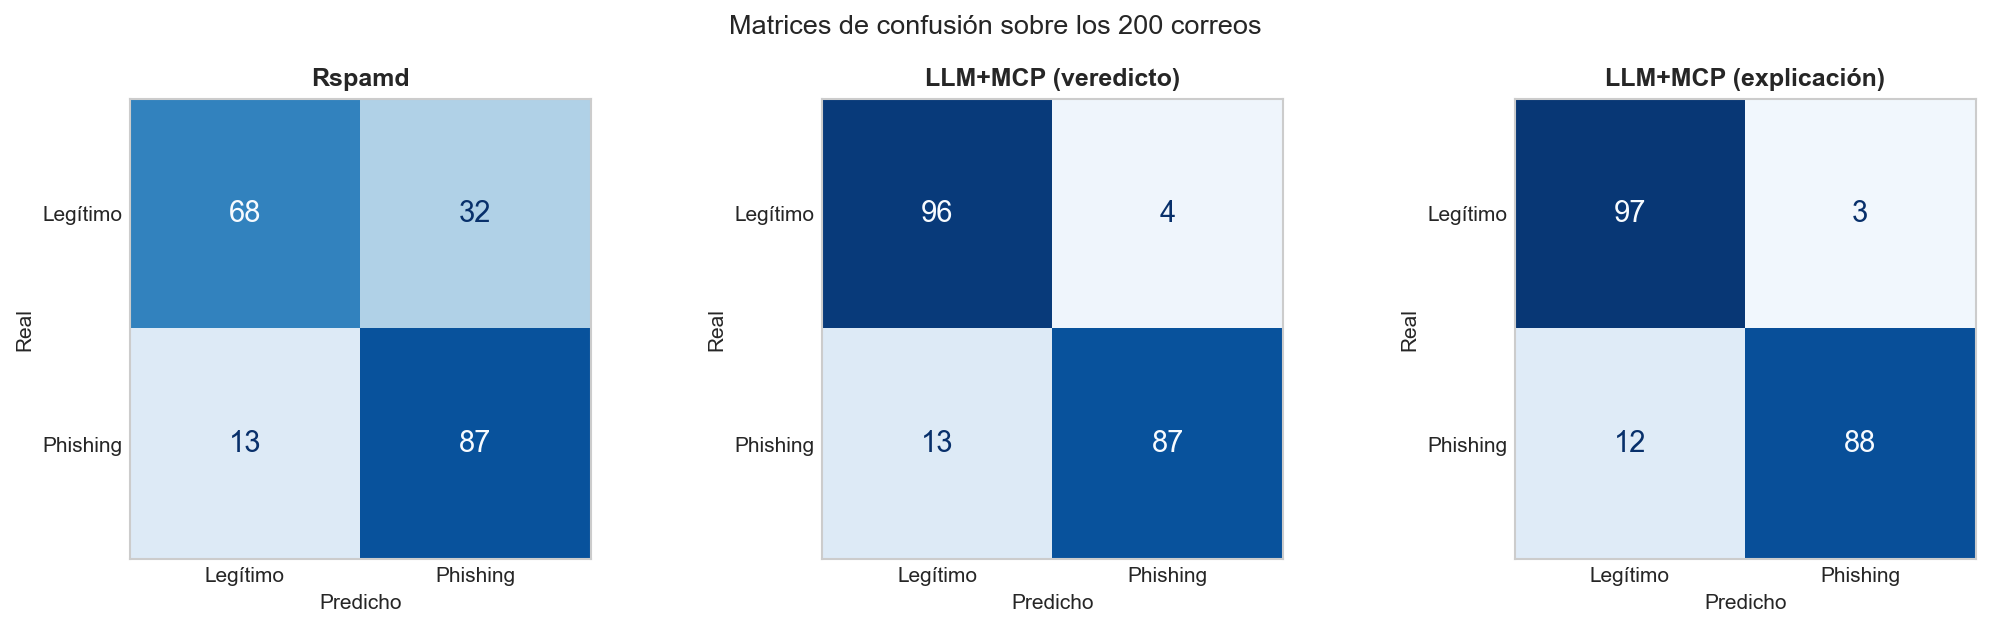

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, (sistema, info) in zip(axes, SISTEMAS.items()):
    y, pred, _ = datos_sistema(sistema)
    ConfusionMatrixDisplay.from_predictions(
        y, pred, labels=[0, 1], display_labels=["Legítimo", "Phishing"],
        cmap="Blues", colorbar=False, ax=ax, text_kw={"fontsize": 14},
        im_kw={"vmin": 0, "vmax": 100},
    )
    ax.set_title(info["nombre"], fontweight="bold")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.grid(False)

fig.suptitle("Matrices de confusión sobre los 200 correos", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrices_200.png")
plt.show()

## 5. Tasas de falsos positivos y falsos negativos

- **FPR** = FP / (FP + TN): legítimos marcados como phishing (falsas alarmas).
- **FNR** = FN / (FN + TP): phishing que pasa como legítimo (el error más peligroso).

,FPR,FNR,FP,FN
Rspamd,0.320,0.130,32,13
LLM+MCP (veredicto),0.040,0.130,4,13
LLM+MCP (explicación),0.030,0.120,3,12


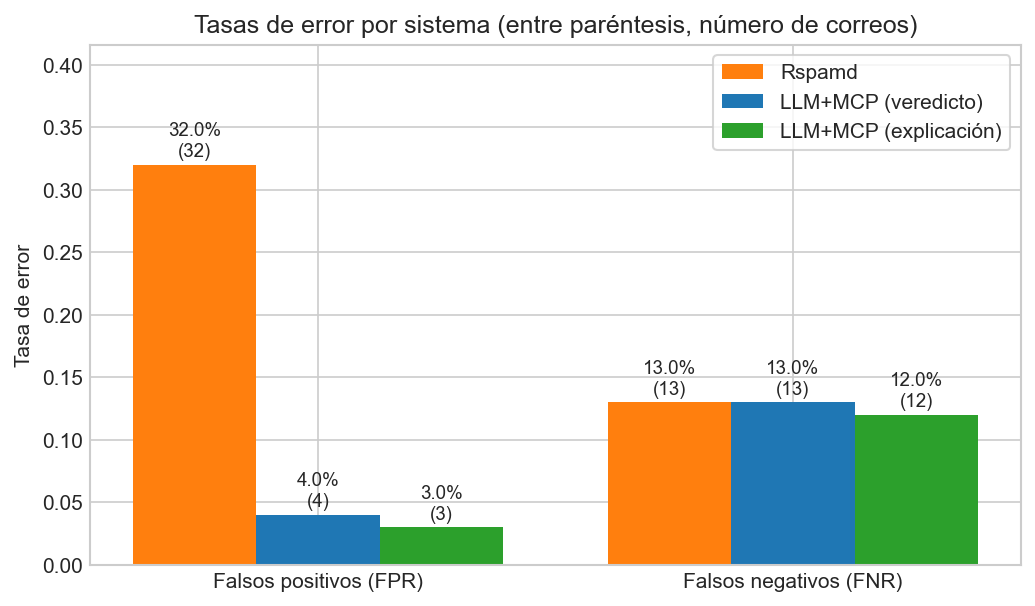

In [7]:
tasas = tabla_metricas[["FPR", "FNR", "FP", "FN"]]
display(tasas.style.format("{:.3f}", subset=["FPR", "FNR"]))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
ancho = 0.26
for k, (sistema, info) in enumerate(SISTEMAS.items()):
    valores = tasas.loc[info["nombre"], ["FPR", "FNR"]].astype(float).to_numpy()
    conteos = tasas.loc[info["nombre"], ["FP", "FN"]].to_numpy()
    barras = ax.bar(x + (k - 1) * ancho, valores, ancho, color=info["color"], label=info["nombre"])
    ax.bar_label(barras, labels=[f"{v:.1%}\n({int(c)})" for v, c in zip(valores, conteos)], padding=2, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(["Falsos positivos (FPR)", "Falsos negativos (FNR)"])
ax.set_ylabel("Tasa de error")
ax.set_ylim(0, tasas[["FPR", "FNR"]].to_numpy().astype(float).max() * 1.3)
ax.set_title("Tasas de error por sistema (entre paréntesis, número de correos)")
ax.legend(frameon=True)
fig.savefig(FIGURES_DIR / "error_rates_200.png")
plt.show()

## 6. Curvas ROC

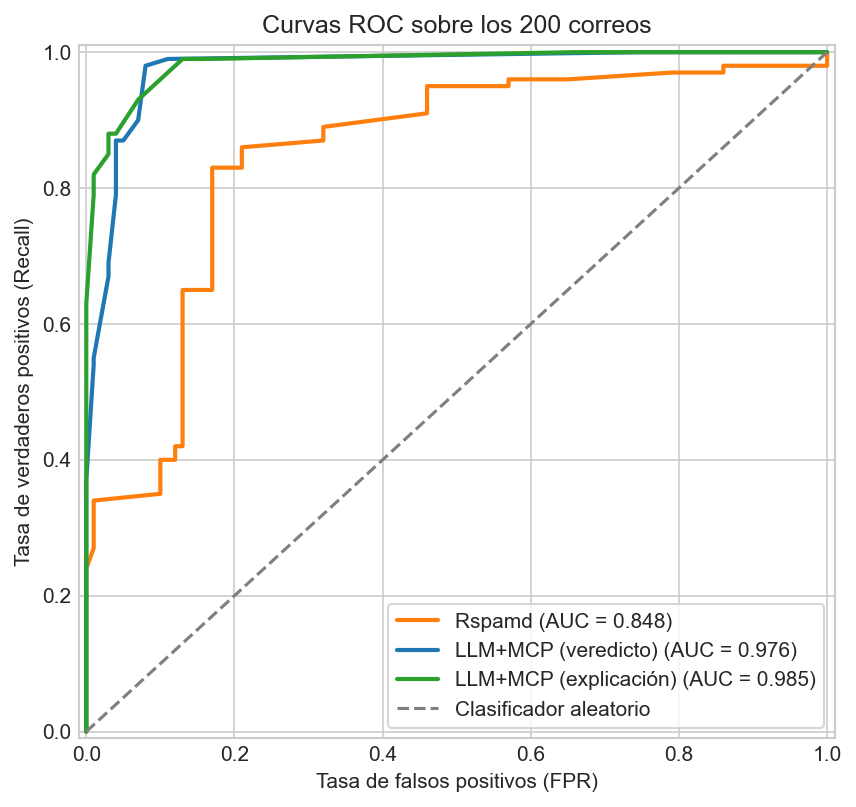

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 6))

for sistema, info in SISTEMAS.items():
    y, _, score = datos_sistema(sistema)
    fpr, tpr, _ = roc_curve(y, score)
    ax.plot(fpr, tpr, color=info["color"], linewidth=2, label=f"{info['nombre']} (AUC = {roc_auc_score(y, score):.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador aleatorio")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_title("Curvas ROC sobre los 200 correos")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.legend(loc="lower right", frameon=True)
fig.savefig(FIGURES_DIR / "roc_curves_200.png")
plt.show()

## 7. Casos donde los sistemas difieren

Primero el patrón de aciertos entre los tres sistemas; después, par a par, cuántos correos acierta solo uno
de los dos (prueba de McNemar exacta); y al final el detalle de los correos donde veredicto y explicación
dan una clasificación distinta.

In [9]:
# Solo correos con resultado en los tres sistemas
completos = df[df[[f"{s}_pred" for s in SISTEMAS]].notna().all(axis=1)].copy()
for sistema in SISTEMAS:
    completos[f"{sistema}_ok"] = completos[f"{sistema}_pred"].astype(int) == completos["label"]

# Patrón de aciertos: qué combinación de sistemas clasifica bien cada correo
def patron(fila) -> str:
    bien = [SISTEMAS[s]["nombre"] for s in SISTEMAS if fila[f"{s}_ok"]]
    if len(bien) == len(SISTEMAS):
        return "Los tres aciertan"
    if not bien:
        return "Los tres fallan"
    return "Solo acierta(n): " + " + ".join(bien)


completos["patron"] = completos.apply(patron, axis=1)
clase = completos["label"].map({0: "Legítimos", 1: "Phishing"})
tabla_patron = pd.crosstab(completos["patron"], clase)
tabla_patron.columns.name = None
tabla_patron.insert(0, "Correos", tabla_patron.sum(axis=1))
tabla_patron.insert(1, "% del total", (tabla_patron["Correos"] / len(completos) * 100).round(1))
tabla_patron.sort_values("Correos", ascending=False)

,Correos,% del total,Legítimos,Phishing
patron,,,,
Los tres aciertan,140,70.0,65,75
Solo acierta(n): LLM+MCP (veredicto) + LLM+MCP (explicación),42,21.0,31,11
Solo acierta(n): Rspamd,14,7.0,3,11
Solo acierta(n): LLM+MCP (explicación),2,1.0,1,1
Solo acierta(n): LLM+MCP (veredicto),1,0.5,0,1
Solo acierta(n): Rspamd + LLM+MCP (explicación),1,0.5,0,1


In [10]:
# Comparación par a par: correos donde solo acierta uno de los dos y prueba de McNemar exacta
pares = [("explicacion", "veredicto"), ("explicacion", "rspamd"), ("veredicto", "rspamd")]
filas = []
for a, b in pares:
    solo_a = int((completos[f"{a}_ok"] & ~completos[f"{b}_ok"]).sum())
    solo_b = int((~completos[f"{a}_ok"] & completos[f"{b}_ok"]).sum())
    p = binomtest(min(solo_a, solo_b), solo_a + solo_b, 0.5).pvalue if (solo_a + solo_b) else np.nan
    filas.append({
        "Par": f"{SISTEMAS[a]['nombre']} vs. {SISTEMAS[b]['nombre']}",
        "Clasificación distinta": int((completos[f"{a}_pred"] != completos[f"{b}_pred"]).sum()),
        "Solo acierta el primero": solo_a,
        "Solo acierta el segundo": solo_b,
        "Ambos fallan": int((~completos[f"{a}_ok"] & ~completos[f"{b}_ok"]).sum()),
        "McNemar p": p,
    })
pd.DataFrame(filas).set_index("Par").style.format({"McNemar p": "{:.4f}"})

,Clasificación distinta,Solo acierta el primero,Solo acierta el segundo,Ambos fallan,McNemar p
Par,,,,,
LLM+MCP (explicación) vs. LLM+MCP (veredicto),4,3,1,14,0.6250
LLM+MCP (explicación) vs. Rspamd,58,44,14,1,0.0001
LLM+MCP (veredicto) vs. Rspamd,58,43,15,2,0.0003


In [11]:
# Detalle: correos donde veredicto y explicación difieren en su clasificación
difieren = completos[completos["veredicto_pred"] != completos["explicacion_pred"]].copy()
difieren["acierta"] = np.where(difieren["veredicto_ok"], "veredicto", "explicación")

print(f"Correos donde veredicto y explicación difieren: {len(difieren)} de {len(completos)}")
print(difieren["acierta"].value_counts().rename("correos en que acierta cada modo").to_string())

difieren[["id", "lote", "label", "veredicto_score", "explicacion_score", "veredicto_pred", "explicacion_pred",
          "rspamd_pred", "acierta"]].reset_index(drop=True)

Correos donde veredicto y explicación difieren: 4 de 200
acierta
explicación    3
veredicto      1


,id,lote,label,veredicto_score,explicacion_score,veredicto_pred,explicacion_pred,rspamd_pred,acierta
0,phishing_pot_sample-1252,1-100,1,0.15,0.65,0,1,0,explicación
1,trec_2007_384,1-100,0,0.72,0.25,1,0,1,explicación
2,phishing_pot_sample-1254,1-100,1,0.65,0.15,1,0,0,veredicto
3,phishing_pot_sample-1376,1-100,1,0.15,0.68,0,1,1,explicación


In [12]:
# Errores que comparten los dos modos del LLM: no dependen de los servidores MCP adicionales
compartidos = completos[~completos["veredicto_ok"] & ~completos["explicacion_ok"]]
print(f"Errores compartidos por veredicto y explicación: {len(compartidos)} "
      f"(phishing no detectado: {int((compartidos['label'] == 1).sum())}, "
      f"legítimos marcados: {int((compartidos['label'] == 0).sum())})")
print(f"De esos, Rspamd clasifica bien: {int(compartidos['rspamd_ok'].sum())}")
compartidos[["id", "lote", "label", "rspamd_score", "rspamd_pred", "veredicto_score", "explicacion_score"]].reset_index(drop=True)

Errores compartidos por veredicto y explicación: 14 (phishing no detectado: 11, legítimos marcados: 3)
De esos, Rspamd clasifica bien: 14


,id,lote,label,rspamd_score,rspamd_pred,veredicto_score,explicacion_score
0,trec_2007_438,1-100,0,0.250000,0,0.85,0.72
1,trec_2007_329,1-100,0,0.200000,0,0.78,0.85
2,phishing_pot_sample-1309,1-100,1,0.490000,1,0.15,0.25
3,phishing_pot_sample-1080,1-100,1,0.527500,1,0.15,0.25
4,phishing_pot_sample-1364,1-100,1,0.360500,1,0.25,0.25
5,phishing_pot_sample-1353,1-100,1,0.669500,1,0.15,0.15
6,phishing_pot_sample-1368,1-100,1,0.450000,1,0.25,0.15
7,phishing_pot_sample-1427,1-100,1,0.445415,1,0.25,0.25
8,phishing_pot_sample-1141,101-200,1,0.314500,1,0.15,0.15
9,phishing_pot_sample-1410,101-200,1,0.332609,1,0.15,0.15


## 8. Comparación visual de los tres sistemas

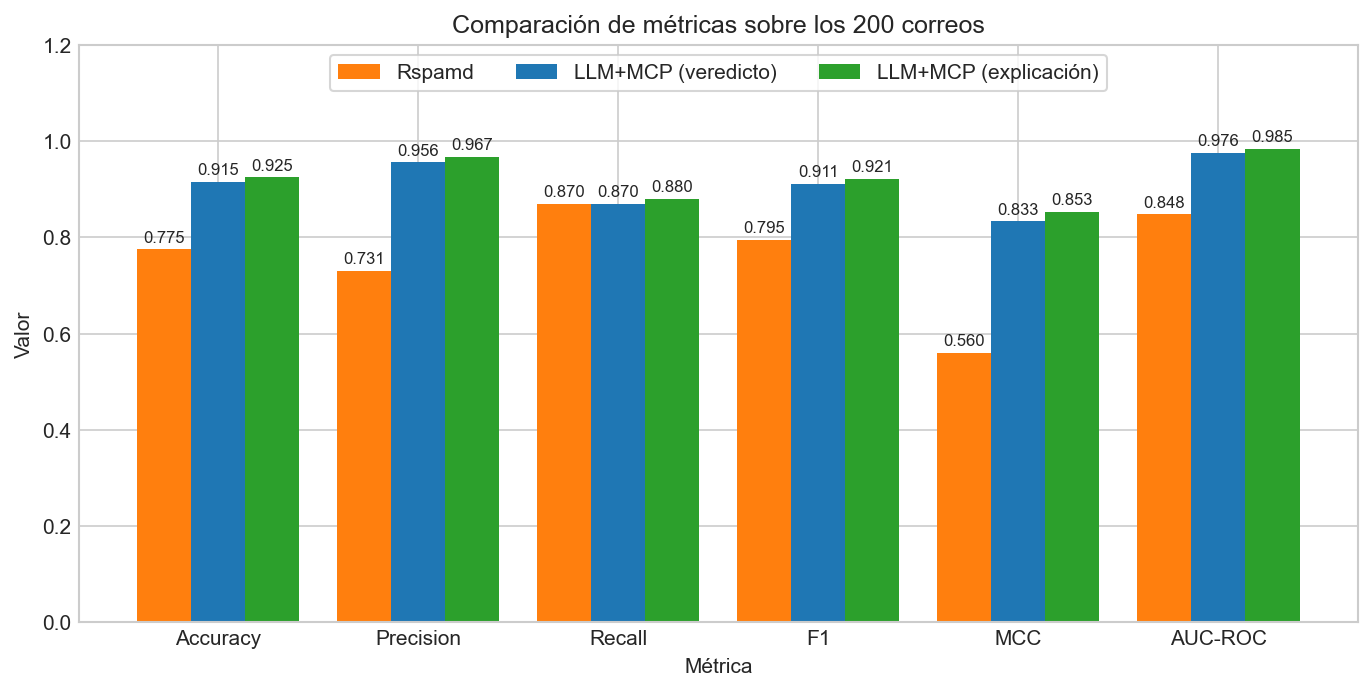

In [13]:
# Barras agrupadas con las métricas principales
x = np.arange(len(METRICAS))
ancho = 0.27

fig, ax = plt.subplots(figsize=(11, 5))
for k, (sistema, info) in enumerate(SISTEMAS.items()):
    barras = ax.bar(x + (k - 1) * ancho, tabla_metricas.loc[info["nombre"], METRICAS].astype(float), ancho,
                    color=info["color"], label=info["nombre"])
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(METRICAS)
ax.set_ylim(0, 1.2)
ax.set_xlabel("Métrica")
ax.set_ylabel("Valor")
ax.set_title("Comparación de métricas sobre los 200 correos")
ax.legend(loc="upper center", ncol=3, frameon=True)
fig.savefig(FIGURES_DIR / "metrics_comparison_200.png")
plt.show()

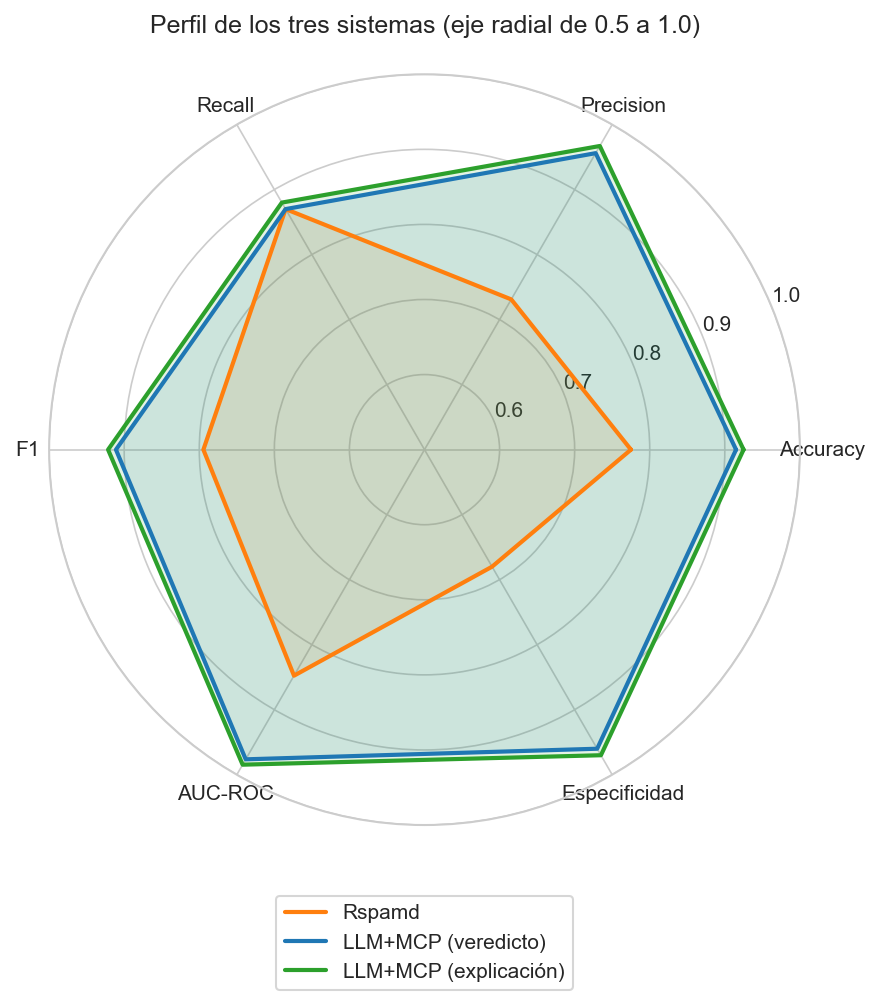

In [14]:
# Gráfico de radar: mismas métricas, más la especificidad (1 - FPR) para que "más afuera" sea siempre mejor
ejes = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC", "Especificidad"]
radar = tabla_metricas[["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]].astype(float).copy()
radar["Especificidad"] = 1 - tabla_metricas["FPR"].astype(float)

angulos = np.linspace(0, 2 * np.pi, len(ejes), endpoint=False).tolist()
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw={"polar": True})
for sistema, info in SISTEMAS.items():
    valores = radar.loc[info["nombre"], ejes].tolist()
    valores += valores[:1]
    ax.plot(angulos, valores, color=info["color"], linewidth=2, label=info["nombre"])
    ax.fill(angulos, valores, color=info["color"], alpha=0.12)

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(ejes)
ax.set_ylim(0.5, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_title("Perfil de los tres sistemas (eje radial de 0.5 a 1.0)", pad=20)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=1, frameon=True)
fig.savefig(FIGURES_DIR / "radar_200.png")
plt.show()

## 9. Lote 1–100 vs. lote 101–200

El modo explicación se corrió en dos tandas. Aquí se revisa si su rendimiento cambió de una a otra.

Rspamd y el modo veredicto sirven de control: sus resultados para los 200 correos salen de **una sola corrida**
sobre los 1,000, así que cualquier diferencia entre lotes en esos dos sistemas se debe a los correos que
cayeron en cada lote, no a un cambio del sistema.

In [15]:
# Métricas de cada sistema en cada lote
filas = {}
for sistema, info in SISTEMAS.items():
    for lote in LOTES:
        filas[(info["nombre"], lote)] = metricas(*datos_sistema(sistema, df[df["lote"] == lote]))

por_lote = pd.DataFrame(filas).T
por_lote[ENTERAS] = por_lote[ENTERAS].astype(int)
por_lote.index.names = ["Sistema", "Lote"]
por_lote.style.format("{:.3f}", subset=METRICAS + TASAS_ERROR)

In [16]:
# Cambio del lote 1-100 al 101-200 por sistema, y prueba exacta de Fisher sobre los aciertos
cambios = []
for sistema, info in SISTEMAS.items():
    a, b = por_lote.loc[(info["nombre"], "1-100")], por_lote.loc[(info["nombre"], "101-200")]
    aciertos = [[a["TP"] + a["TN"], a["FP"] + a["FN"]], [b["TP"] + b["TN"], b["FP"] + b["FN"]]]
    cambios.append({
        "Sistema": info["nombre"],
        "Δ Accuracy": b["Accuracy"] - a["Accuracy"],
        "Δ Recall": b["Recall"] - a["Recall"],
        "Δ F1": b["F1"] - a["F1"],
        "Errores 1-100": int(a["FP"] + a["FN"]),
        "Errores 101-200": int(b["FP"] + b["FN"]),
        "Fisher p (aciertos entre lotes)": fisher_exact(aciertos)[1],
    })
pd.DataFrame(cambios).set_index("Sistema").style.format(
    {"Δ Accuracy": "{:+.3f}", "Δ Recall": "{:+.3f}", "Δ F1": "{:+.3f}", "Fisher p (aciertos entre lotes)": "{:.3f}"})

,Δ Accuracy,Δ Recall,Δ F1,Errores 1-100,Errores 101-200,Fisher p (aciertos entre lotes)
Sistema,,,,,,
Rspamd,+0.070,+0.060,+0.062,26,19,0.310
LLM+MCP (veredicto),+0.050,+0.060,+0.053,11,6,0.311
LLM+MCP (explicación),+0.030,+0.040,+0.032,9,6,0.593


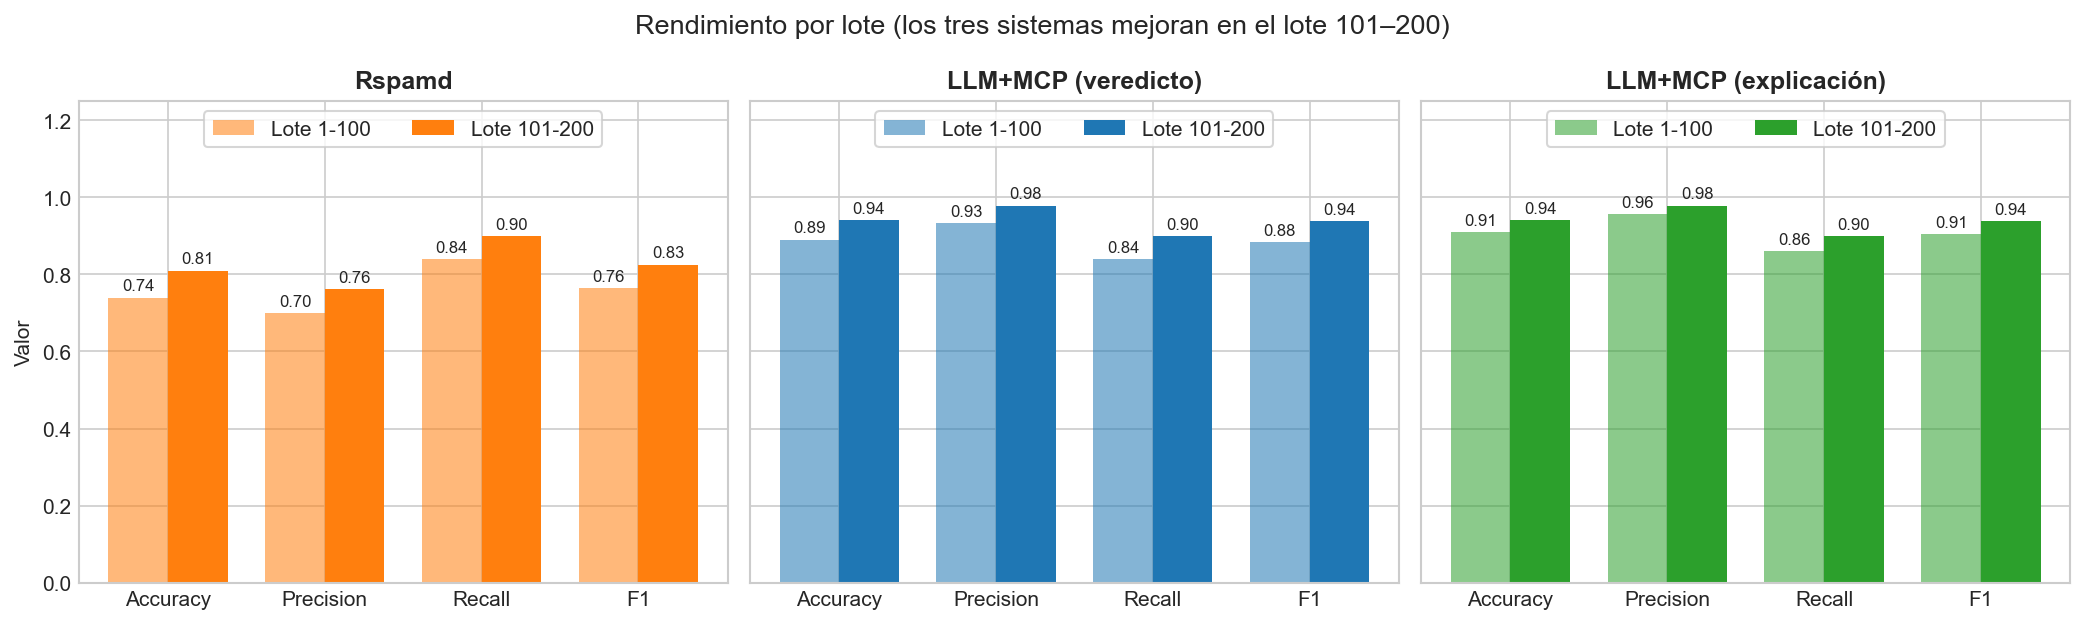

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
metricas_lote = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metricas_lote))
ancho = 0.38

for ax, (sistema, info) in zip(axes, SISTEMAS.items()):
    for k, (lote, alpha) in enumerate(zip(LOTES, [0.55, 1.0])):
        valores = por_lote.loc[(info["nombre"], lote), metricas_lote].astype(float)
        barras = ax.bar(x + (k - 0.5) * ancho, valores, ancho, color=info["color"], alpha=alpha, label=f"Lote {lote}")
        ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(metricas_lote)
    ax.set_ylim(0, 1.25)
    ax.set_title(info["nombre"], fontweight="bold")
    ax.legend(loc="upper center", ncol=2, frameon=True)

axes[0].set_ylabel("Valor")
fig.suptitle("Rendimiento por lote (los tres sistemas mejoran en el lote 101–200)", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "batch_comparison_200.png")
plt.show()

In [18]:
# Comportamiento operativo del modo explicación en cada lote (tiempos, señales, herramientas, VirusTotal)
def resumen_operativo(tabla: pd.DataFrame) -> dict:
    herramientas = tabla["herramientas_invocadas"].dropna()
    vt = [h for lista in herramientas for h in lista if h.get("servidor") == "virustotal"]
    return {
        "Correos": len(tabla),
        "Tiempo mediano por correo (s)": round(tabla["explicacion_tiempo_ms"].median() / 1000, 1),
        "Tiempo máximo (s)": round(tabla["explicacion_tiempo_ms"].max() / 1000, 1),
        "Señales por correo (media)": round(tabla["senales_count"].mean(), 2),
        "Correos sin ninguna señal": int((tabla["senales_count"] == 0).sum()),
        "Llamadas a herramientas por correo (media)": round(herramientas.str.len().mean(), 2),
        "Consultas a VirusTotal": len(vt),
        "Consultas a VirusTotal fallidas": sum(not h.get("ok") for h in vt),
        "Puntaje medio en phishing": round(tabla.loc[tabla["label"] == 1, "explicacion_score"].mean(), 3),
        "Puntaje medio en legítimos": round(tabla.loc[tabla["label"] == 0, "explicacion_score"].mean(), 3),
    }


pd.DataFrame({f"Lote {lote}": resumen_operativo(df[df["lote"] == lote]) for lote in LOTES}).map(lambda v: f'{v:g}')

,Lote 1-100,Lote 101-200
Correos,100,100
Tiempo mediano por correo (s),63.9,62
Tiempo máximo (s),243.9,445.7
Señales por correo (media),6.35,6.3
Correos sin ninguna señal,1,0
Llamadas a herramientas por correo (media),7.64,7.36
Consultas a VirusTotal,290,248
Consultas a VirusTotal fallidas,38,21
Puntaje medio en phishing,0.795,0.832
Puntaje medio en legítimos,0.091,0.063


## 10. Resumen para el capítulo de resultados

> Cifras de las corridas del 2026-10-04. Si se regenera algún archivo de resultados, actualizar estas tablas con las de las secciones 3 y 9.

**Tabla. Desempeño de los tres sistemas sobre 200 correos (100 phishing, 100 legítimos).**

| Sistema | Accuracy | Precision | Recall | F1 | MCC | AUC-ROC | FP | FN |
|---|---|---|---|---|---|---|---|---|
| Rspamd (umbral 6.0) | 0.775 | 0.731 | 0.870 | 0.795 | 0.560 | 0.848 | 32 | 13 |
| LLM+MCP, modo veredicto | 0.915 | 0.956 | 0.870 | 0.911 | 0.833 | 0.976 | 4 | 13 |
| LLM+MCP, modo explicación | **0.925** | **0.967** | **0.880** | **0.921** | **0.853** | **0.985** | **3** | **12** |

**Tabla. Modo explicación por lote.**

| Lote | Accuracy | Precision | Recall | F1 | FP | FN | Tiempo mediano por correo |
|---|---|---|---|---|---|---|---|
| 1–100 | 0.910 | 0.956 | 0.860 | 0.905 | 2 | 7 | 63.9 s |
| 101–200 | 0.940 | 0.978 | 0.900 | 0.938 | 1 | 5 | 62.0 s |

**Lectura.**

- **Los dos modos del LLM superan a Rspamd con claridad, y la diferencia es significativa** (McNemar exacta,
  p < 0.001 en ambos casos). Detectan prácticamente el mismo phishing (Recall 0.87–0.88 en los tres), pero
  Rspamd marca como phishing 32 de los 100 legítimos, frente a 4 y 3 de los modos del LLM.
- **El modo explicación y el modo veredicto son estadísticamente indistinguibles.** Discrepan en 4 de los 200
  correos (el modo explicación acierta 3 y el veredicto 1; McNemar p = 0.63) y los 4 están en el primer lote:
  en el lote 101–200 los dos modos dieron la misma clasificación en los 100 correos. Con 200 correos se
  sostiene lo que se veía con 100: usar los cuatro servidores MCP no degrada la clasificación, pero tampoco
  hay evidencia de que la mejore; su aporte es la explicación, no el veredicto.
- **Los errores del LLM son los mismos en ambos modos y Rspamd los acierta todos.** Los dos modos comparten 14
  errores (11 phishing no detectados y 3 legítimos marcados), y Rspamd clasifica bien los 14. Solo hay un
  phishing que no detectan ni Rspamd ni el modo explicación. Esto refuerza la complementariedad observada en
  los 1,000 correos.
- **Lote 1–100 vs. 101–200: el modo explicación es consistente, no mejoró ni se degradó.** Sus métricas son más
  altas en el segundo lote (Accuracy 0.91 → 0.94, F1 0.905 → 0.938), pero Rspamd y el modo veredicto, cuyos
  resultados salen de una única corrida, suben igual o más en ese mismo lote (Rspamd +0.07 de Accuracy,
  veredicto +0.05, explicación +0.03). La diferencia se debe a que los correos del segundo lote son algo más
  fáciles, no a un cambio del sistema, y en ningún caso es significativa (Fisher p = 0.59 para explicación).
  El comportamiento operativo también es estable: 64 s y 62 s de mediana por correo, 6.35 y 6.30 señales por
  correo.
- Los resultados sobre 200 coinciden con los de los 1,000 correos para los sistemas que se evaluaron en ambos
  (veredicto: F1 0.911 en los dos; Rspamd: F1 0.795 vs. 0.804).

**Limitaciones a declarar.** (1) Con 200 correos los intervalos de confianza siguen siendo de unos ±4 puntos
en Accuracy y F1; diferencias de uno o dos correos no son concluyentes. (2) El sistema LLM recibió solo el
cuerpo del correo (`body`), mientras que Rspamd recibió el correo con encabezados (`raw_text`). (3) Los
legítimos de TREC tienen encabezados reconstruidos, lo que probablemente infla los falsos positivos de Rspamd.
(4) El costo en tokens del modo explicación no quedó registrado. (5) En el modo explicación fallaron 59 de las
538 consultas a VirusTotal (análisis de URL que no terminó a tiempo o dominios inválidos); esos correos se
evaluaron sin ese dato.